# Assignment 2: Data Preparation (NOAA GHCN-Daily)

**Question:** Has warming in the U.S. been uniform, or is it concentrated in certain regions and seasons?

In [1]:
import os
import requests
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from tqdm import tqdm

os.makedirs("data/raw", exist_ok=True)

## 1. Station list
U.S. Historical Climatology Network (HCN) stations: long, quality-controlled records. `ghcnd-stations.txt` is fixed-width, so `read_fwf` with the column positions from NOAA's readme.

In [2]:
STATIONS_URL = "https://www.ncei.noaa.gov/pub/data/ghcn/daily/ghcnd-stations.txt"

if not os.path.exists("data/raw/ghcnd-stations.txt"):
    with open("data/raw/ghcnd-stations.txt", "w") as f:
        f.write(requests.get(STATIONS_URL, timeout=120).text)

stations = pd.read_fwf("data/raw/ghcnd-stations.txt",
                       colspecs=[(0, 11), (12, 20), (21, 30), (31, 37), (38, 40), (41, 71), (76, 79)],
                       names=["id", "lat", "lon", "elev", "state", "name", "hcn"])
hcn = stations[stations["hcn"] == "HCN"].copy()
hcn["name"] = hcn["name"].str.title()
print(len(hcn), "HCN stations in", hcn["state"].nunique(), "states")

1218 HCN stations in 48 states


Sample 3 stations per state (seeded) so the map covers the whole country without downloading all ~1,200.

In [3]:
SEED = 42
PER_STATE = 3
sample = hcn.groupby("state", group_keys=False).apply(
    lambda g: g.sample(min(len(g), PER_STATE), random_state=SEED))
print(len(sample), "stations sampled")

144 stations sampled


## 2. Download daily records
One CSV per station with one row per day. Files already downloaded are skipped.

In [4]:
ACCESS_URL = "https://www.ncei.noaa.gov/data/global-historical-climatology-network-daily/access/{}.csv"

for sid in tqdm(sample["id"], desc="Downloading"):
    path = f"data/raw/{sid}.csv"
    if os.path.exists(path):
        continue
    r = requests.get(ACCESS_URL.format(sid), timeout=120)
    if r.status_code == 200:
        with open(path, "wb") as f:
            f.write(r.content)

Downloading: 100%|██████████| 144/144 [02:28<00:00,  1.03s/it]


## 3. Daily → monthly
Values are in tenths (°C, mm), so divide by 10. A value whose quality flag (2nd field of `*_ATTRIBUTES`) is non-blank failed NOAA's checks and is dropped.

In [5]:
def load_station(sid):
    d = pd.read_csv(f"data/raw/{sid}.csv", low_memory=False,
                    usecols=lambda c: c in {"DATE", "TMAX", "TMIN", "PRCP",
                                            "TMAX_ATTRIBUTES", "TMIN_ATTRIBUTES", "PRCP_ATTRIBUTES"})
    for v in ["TMAX", "TMIN", "PRCP"]:
        if v not in d:
            return None
        qflag = d[f"{v}_ATTRIBUTES"].fillna(",,").str.split(",").str[1]
        d[v] = d[v].where(qflag == "") / 10
    d["DATE"] = pd.to_datetime(d["DATE"])
    d = d[d["DATE"].dt.year.between(1950, 2025)]
    d["id"] = sid
    return d[["id", "DATE", "TMAX", "TMIN", "PRCP"]]

daily = pd.concat([load_station(s) for s in sample["id"] if os.path.exists(f"data/raw/{s}.csv")])
print(daily.describe())   # check: TMAX should mostly be between -20 and 45 °C

                             DATE          TMAX          TMIN          PRCP
count                     3480457  3.385624e+06  3.374408e+06  3.438844e+06
mean   1986-07-02 10:10:12.703676  1.834344e+01  5.343875e+00  2.476109e+00
min           1950-01-01 00:00:00 -3.330000e+01 -5.110000e+01  0.000000e+00
25%           1968-06-22 00:00:00  1.000000e+01 -1.700000e+00  0.000000e+00
50%           1986-05-01 00:00:00  2.000000e+01  5.600000e+00  0.000000e+00
75%           2003-11-29 00:00:00  2.780000e+01  1.390000e+01  5.000000e-01
max           2025-12-31 00:00:00  4.890000e+01  3.500000e+01  4.343000e+02
std                           NaN  1.152960e+01  1.067432e+01  7.898000e+00


In [6]:
daily["year"] = daily["DATE"].dt.year
daily["month"] = daily["DATE"].dt.month
daily["TAVG"] = (daily["TMAX"] + daily["TMIN"]) / 2

monthly = (daily.groupby(["id", "year", "month"])
                .agg(tavg=("TAVG", "mean"), tmax=("TMAX", "mean"), tmin=("TMIN", "mean"),
                     prcp=("PRCP", "sum"),
                     hot_days=("TMAX", lambda x: (x >= 32.2).sum()),   # 90 °F
                     frost_days=("TMIN", lambda x: (x < 0).sum()),
                     n_days=("TAVG", "count"))
                .reset_index())

# Months with fewer than 20 valid days would be biased, so blank them
monthly.loc[monthly["n_days"] < 20, ["tavg", "tmax", "tmin", "prcp", "hot_days", "frost_days"]] = np.nan
print(monthly.shape)

(114837, 10)


## 4. Check coverage and save
Keep stations with at least 60 years of usable data so trends are comparable.

In [8]:
years_ok = monthly.dropna(subset=["tavg"]).groupby("id")["year"].nunique()
keep = years_ok[years_ok >= 60].index
print(f"Kept {len(keep)} of {len(sample)} stations")

monthly = monthly[monthly["id"].isin(keep)].round(2)
stations_out = hcn[hcn["id"].isin(keep)][["id", "name", "state", "lat", "lon", "elev"]]
monthly.to_csv("data/monthly.csv", index=False)
stations_out.to_csv("data/stations.csv", index=False)

Kept 112 of 144 stations


## 5. Exploratory analysis
Anomaly = each station-month minus that station's 1961–1990 average for the same month.

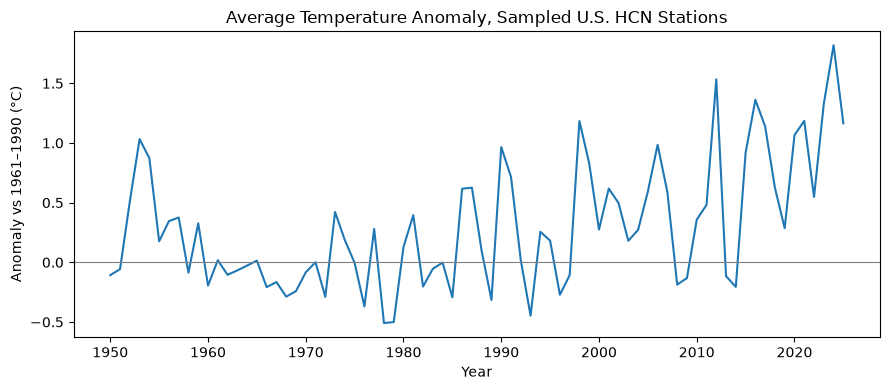

In [9]:
base = (monthly[monthly["year"].between(1961, 1990)]
        .groupby(["id", "month"])["tavg"].mean().rename("base"))
monthly = monthly.join(base, on=["id", "month"])
monthly["anom"] = monthly["tavg"] - monthly["base"]

annual = monthly.groupby("year")["anom"].mean()
fig, ax = plt.subplots(figsize=(9, 4))
ax.plot(annual.index, annual.values)
ax.axhline(0, color="gray", lw=0.8)
ax.set_title("Average Temperature Anomaly, Sampled U.S. HCN Stations")
ax.set_xlabel("Year"); ax.set_ylabel("Anomaly vs 1961–1990 (°C)")
plt.tight_layout(); plt.show()

In [10]:
# Which seasons warmed most? Compare 1991–2025 to the baseline by month
by_month = monthly[monthly["year"] >= 1991].groupby("month")["anom"].mean()
print(by_month.round(2))

month
1     1.11
2     0.77
3     0.49
4     0.15
5     0.32
6     0.46
7     0.46
8     0.53
9     0.69
10    0.29
11    0.09
12    0.94
Name: anom, dtype: float64
